[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/htfa_network_animations.ipynb)

# Brain networks of orders 1 to 4 (with HTFA)

This tutorial computes dynamic correlations of orders 1 to 4 with `tc.features` on fMRI data recorded while people listened to a story, and draws each order as a network on the brain over time. You will learn what the features and correlations of each order are, where on the brain each feature sits, and how to turn them into videos with the [htfa](https://htfa.readthedocs.io/en/latest/) toolbox.

**Data.** The intact-story condition of Simony et al. (2016), *Nature Communications* 7, 12141 ([doi:10.1038/ncomms12141](https://doi.org/10.1038/ncomms12141)), as fit with hierarchical topographic factor analysis (HTFA; Manning et al., 2018, *NeuroImage* 180, 243-252, [doi:10.1016/j.neuroimage.2018.01.071](https://doi.org/10.1016/j.neuroimage.2018.01.071)) by Owen, Chang & Manning (2021), *Nature Communications* 12, 5728 ([doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)). HTFA describes each brain image as a weighted sum of 700 nodes (radial basis functions), so each participant's data is a matrix of node weights (timepoints by nodes). The fit is in the data archive of [github.com/ContextLab/timecorr-paper](https://github.com/ContextLab/timecorr-paper).

On its first run, the notebook downloads a 460 MB archive and keeps the fit in `$TIMECORR_DATA` (default `~/timecorr_data`). Rendering the videos takes most of the run time, which the last cell prints (this run used a GPU and full quality). With fewer than 4 CPU cores, as on a free Colab runtime, the notebook draws smaller preview videos (section 6) and should take about 20 to 25 minutes there (an estimate from the timings of an earlier Colab run).

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.1 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
# bottleneck>=1.5: pandas 3, which the tutorial extras install, warns about the older
# bottleneck that Colab has.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr[tutorials]>=0.3.1" "bottleneck>=1.5" || pip install -q "timecorr[tutorials] @ git+https://github.com/ContextLab/timecorr.git@master" "bottleneck>=1.5"

In [2]:
import io
import os
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from PIL import Image as PILImage

import htfa
from htfa.brainnet import effective_nodes, mni_mask, plot_network
import timecorr as tc

%matplotlib inline
NOTEBOOK_START = time.time()
print('timecorr', tc.__version__, '| htfa', htfa.__version__)

timecorr 0.3.1 | htfa 0.2.0


## 1. Download the fit

`tc.datasets.story_listening` downloads the archive once, keeps only the HTFA fit, checks its SHA-256 checksum and deletes the archive.

In [3]:
K = 100                                          # number of nodes analyzed (section 2)
data, nodes = tc.datasets.story_listening(n_nodes=K, return_nodes=True)
fit_path = tc.datasets.cache_dir() / 'pieman' / 'pieman_posterior_K700.mat'
print(fit_path.name, f'{fit_path.stat().st_size / 1e6:.0f} MB')

pieman_posterior_K700.mat 233 MB


## 2. Choose the nodes

The fit is a MATLAB file, which `tc.datasets.story_listening` reads with `scipy.io.loadmat`. The notebook analyzes 100 of the 700 nodes, which keeps the run short: among the nodes whose weights vary over time in every participant, the function picks them by farthest-point sampling of the node centers (start at the node nearest the middle of all centers, then repeatedly add the node farthest from those already chosen), which spreads them over the brain. Every figure and video below shows these nodes, each drawn at the part of its radial basis function that lies inside an MNI brain mask (`htfa.brainnet.effective_nodes`).

36 participants, 300 timepoints; 679 of 700 nodes vary in every participant; analyzing 100


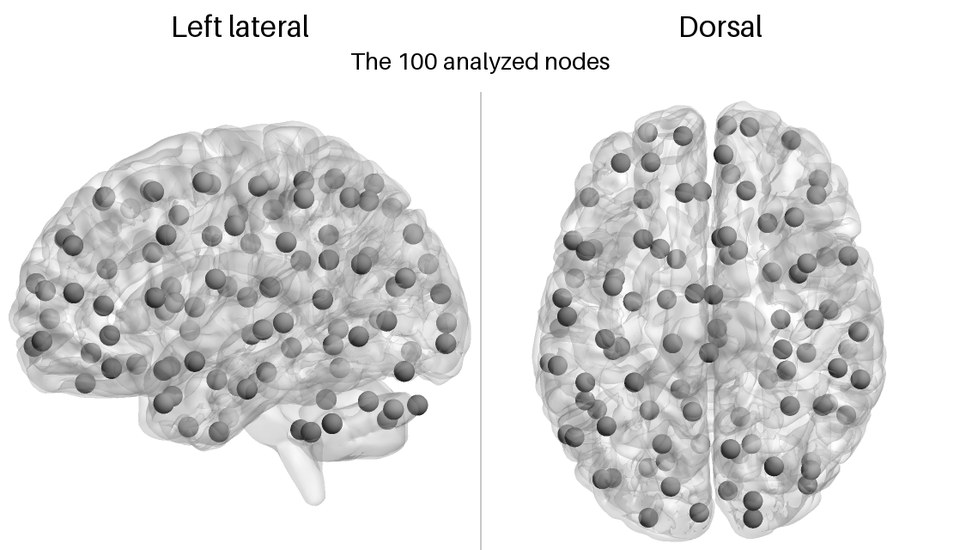

In [4]:
n_participants, T = len(data), len(data[0])      # data: one (timepoints, K) matrix per participant
xyz, _, _ = effective_nodes(nodes['centers'], nodes['widths'], mni_mask())   # centers in MNI mm
print(f'{n_participants} participants, {T} timepoints; {len(nodes["varying"])} of {nodes["total"]} nodes '
      f'vary in every participant; analyzing {K}')


def show_image(img, width=None):
    # display a PIL image as a JPEG
    if width is not None and img.width > width:
        img = img.resize((width, round(img.height * width / img.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    img.convert('RGB').save(buf, format='JPEG', quality=88)
    display(Image(data=buf.getvalue(), format='jpeg'))


show_image(plot_network(xyz, snap=False, size=(880, 550), views=('left', 'dorsal'),
                        caption=f'The {K} analyzed nodes'), width=960)

## 3. Features of orders 1 to 4

For each order `k`, `tc.features` computes two things (see the [higher-order tutorial](higher_order.ipynb) and [tc.features](https://timecorr.readthedocs.io/en/latest/generated/timecorr.features.html)):

- `X[k]`, the order-`k` features: dynamic correlations between the columns of `D[k-1]`, computed across participants with `tc.isfc` and summarized with PCA at order 1 and with `tc.WeightedStrength(signed=True)` above (one magnitude and one signed column per input column);
- `D[k]`, the columns that feed order `k + 1`: within-participant dynamic correlations of `D[k-1]`, summarized with `tc.Communities()` (one column per community of columns), or with one column per input column when the communities give too few columns.

`D[0]` is the node weights. `return_delta=True` also returns `D`, and `return_info=True` returns a record of each step, printed below.

In [5]:
start = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', UserWarning)  # timecorr warns with UserWarning
    (X, D), info = tc.features(data, order=4, return_delta=True, return_info=True)
caught = [w for w in caught if issubclass(w.category, UserWarning)]  # timecorr's warnings only
print(f'tc.features: {time.time() - start:.0f} s')
for w in caught:
    print(f'{w.category.__name__}: {w.message}')
# the columns that are constant over time, from the record of each step (one list per participant;
# magnitude columns come first, then the signed ones)
for name, out, path in (('X', X, 'analysis'), ('D', D, 'feeding')):
    for step in (s for s in info if s['path'] == path):
        for p, columns in enumerate(step['constant_columns']):
            x, k = out[step['order']][p], step['order']
            for c in columns:
                kind = 'magnitude' if name == 'X' and c < x.shape[1] // 2 else 'column'
                print(f'constant: {name}[{k}][{p}][:, {c}] ({kind}), value {x[0, c]:.3g}')
print()
print(f'{"order":>5} {"path":>9} {"input":>6} {"output":>7}  summary used')
for step in info:
    used = step['effective'].split('(')[0]
    if step.get('fallback'):
        used += f' (communities gave {step["n_communities"]} column(s): {step["fallback"]})'
    print(f'{step["order"]:>5} {step["path"]:>9} {step["input_width"]:>6} {step["output_width"]:>7}  {used}')

tc.features: 38 s
constant: X[4][31][:, 3] (magnitude), value 0

order      path  input  output  summary used
    1  analysis    100     100  PCA
    1   feeding    100     100  WeightedStrength (communities gave 2 column(s): too_few_community_columns)
    2  analysis    100     200  WeightedStrength
    2   feeding    100       4  Communities
    3  analysis      4       8  WeightedStrength
    3   feeding      4       4  WeightedStrength (communities gave 1 column(s): too_few_community_columns)
    4  analysis      4       8  WeightedStrength
    4   feeding      4       4  WeightedStrength (communities gave 1 column(s): too_few_community_columns)


The table shows which summary each feeding step used. The warning is about the constant column printed below it: a magnitude column of one participant that is 0 at every timepoint, because all of that feature's pair weights are in the low group that centering subtracts (`a_ij = max(w_ij - m, 0)` in `tc.WeightedStrength`).

## 4. Where each feature sits on the brain

Each column of `D[k]` belongs to a set of nodes. A column of `D[0]` is one node. A step that keeps one column per input column keeps the input's node sets, and a community column belongs to the union of its members' sets (a community of one member emits no column). The record of a step that used communities gives the memberships as `"labels"`, the community of each input column. Each feature is placed at the centroid of its nodes.

In [6]:
# node_sets[k][i]: the analyzed nodes (indices into xyz) that column i of D[k] belongs to
node_sets = {0: [np.array([i]) for i in range(K)]}
for step in (s for s in info if s['path'] == 'feeding'):
    k, prev = step['order'], node_sets[step['order'] - 1]
    if step['labels'] is not None:
        labels = np.array(step['labels'])
        groups = [np.flatnonzero(labels == g) for g in np.unique(labels)]
        groups = sorted((g for g in groups if len(g) >= 2), key=lambda g: g.min())
        node_sets[k] = [np.concatenate([prev[j] for j in g]) for g in groups]
    else:
        node_sets[k] = prev
    assert len(node_sets[k]) == step['output_width']   # one set per column of D[k]
    sets = node_sets[k]
    sizes = ', '.join(str(len(s)) for s in sets) if len(sets) <= 10 else f'{sorted({len(s) for s in sets})}'
    print(f'D[{k}]: {len(sets)} columns; nodes per column: {sizes}')
positions = {k: np.array([xyz[s].mean(axis=0) for s in sets]) for k, sets in node_sets.items()}

D[1]: 100 columns; nodes per column: [1]
D[2]: 4 columns; nodes per column: 22, 36, 16, 26
D[3]: 4 columns; nodes per column: 22, 36, 16, 26
D[4]: 4 columns; nodes per column: 22, 36, 16, 26


The cell below defines how features are drawn: when the features of an order are communities, each community gets its own color, used for its member nodes and for the sphere at its centroid. The colors come from colorblind-safe palettes without red or blue, which mark the signs of edges. It then draws the communities. The second view is dorsal, or posterior when that separates the community centroids better.

order 1: 100 features (single nodes); views: left lateral, dorsal
order 2: 100 features (single nodes); views: left lateral, dorsal
order 3: 4 features (communities); views: left lateral, dorsal
order 4: 4 features (communities); views: left lateral, dorsal


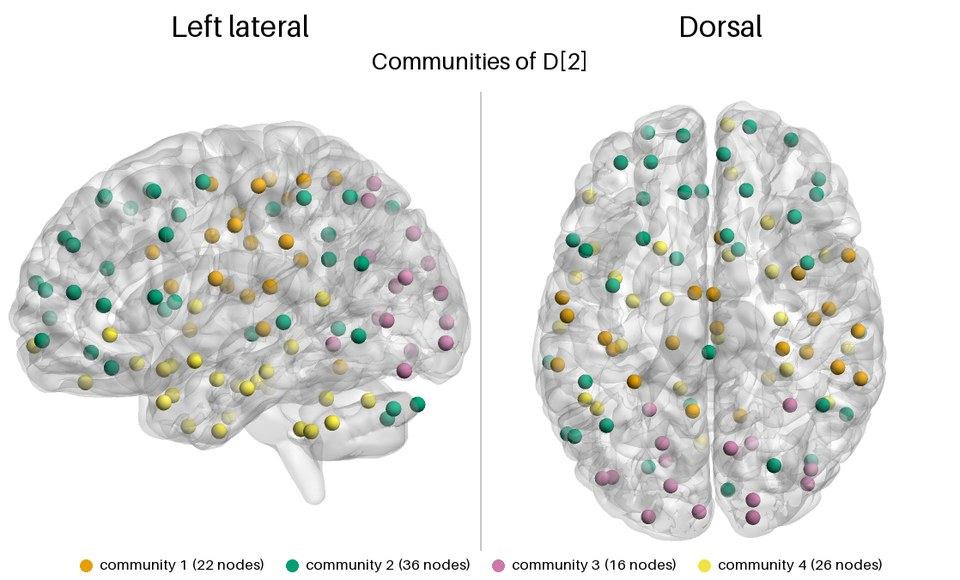

In [7]:
from htfa.brainnet import VIEWS as VIEW_DIRECTIONS
from matplotlib.colors import to_hex

GRAY = '#808080'
# Okabe-Ito and Paul Tol colors without red or blue (red and blue mark edge signs)
PALETTE = ['#E69F00', '#009E73', '#CC79A7', '#F0E442', '#000000', '#999933', '#44AA99', '#DDCC77']


def group_colors(n):
    # n distinct colors (Tableau colors after the first 8)
    extra = [to_hex(c) for c in plt.cm.tab20b(np.linspace(0, 1, max(n - len(PALETTE), 1)))]
    return (PALETTE + extra)[:n]


# drawing of the features of each order k (columns of D[k-1]); the number of groups is
# the width of the feeding step that made D[k-1], read from return_info
widths_D = {0: K} | {s['order']: s['output_width'] for s in info if s['path'] == 'feeding'}
features_of = {}
for k in range(1, 5):
    sets = node_sets[k - 1]
    assert len(sets) == widths_D[k - 1]
    grouped = any(len(s) > 1 for s in sets)
    colors = group_colors(len(sets)) if grouped else [GRAY] * len(sets)
    node_colors = [GRAY] * K                      # nodes in no group stay gray
    for s, c in zip(sets, colors):
        for i in s:
            node_colors[i] = c
    second = 'dorsal'
    if grouped:
        def separation(view):
            d = np.asarray(VIEW_DIRECTIONS[view][0])
            p = positions[k - 1] - np.outer(positions[k - 1] @ d, d)   # projected centroids
            return min((np.linalg.norm(a - b) for n, a in enumerate(p) for b in p[n + 1:]), default=np.inf)
        second = max(('dorsal', 'posterior'), key=separation)
    legend = [(c, f'community {g + 1} ({len(s)} nodes)', 'dot') for g, (s, c) in enumerate(zip(sets, colors))]
    features_of[k] = dict(grouped=grouped, colors=colors, node_colors=node_colors,
                          views=('left', second), legend=legend if grouped else [])
    print(f'order {k}: {len(sets)} features ({"communities" if grouped else "single nodes"}); '
          f'views: left lateral, {second}')

for k in (s['order'] for s in info if s.get('labels')):
    f = features_of[k + 1]                       # the order whose features are these communities
    # no edges; spheres of radius 3 mm (radius_kb: sizes are radii in mm) at the given centers (snap=False)
    show_image(plot_network(xyz, sizes=np.full(K, 3.0), radius_kb=(1.0, 0.0), node_color=f['node_colors'],
                            snap=False, views=f['views'], size=(880, 550),
                            caption=f'Communities of D[{k}]', legend=f['legend']), width=960)

## 5. Correlations of each order

An order-`k` correlation is a dynamic correlation between two columns of `D[k-1]`, that is, between two order-`(k-1)` features. The cell below computes them with `tc.timecorr` (the kernel and `cfun` that `tc.features` uses), checks that summarizing them as `tc.features` does gives `X[k]` again, and averages them over participants with `tc.corrmean_combine`.

In [8]:
R, values, messages = {}, {}, []
for k in range(1, 5):
    corrs = tc.timecorr(D[k - 1], cfun=tc.isfc, combine=tc.null_combine)
    summary = 'PCA' if k == 1 else tc.WeightedStrength(signed=True)
    step = next(s for s in info if s['order'] == k and s['path'] == 'analysis')
    assert step['effective'] == (summary if k == 1 else repr(summary))
    with warnings.catch_warnings(record=True) as caught_reduce:
        warnings.simplefilter('always', UserWarning)  # timecorr warns with UserWarning
        again = tc.reduce(corrs, rfun=summary)
    caught_reduce = [w for w in caught_reduce if issubclass(w.category, UserWarning)]  # timecorr's warnings only
    messages += [str(w.message) for w in caught_reduce]
    assert all(np.allclose(a, b, rtol=1e-8, atol=1e-8 * np.abs(b).max()) for a, b in zip(again, X[k]))
    R[k] = tc.vec2mat(tc.corrmean_combine(corrs))            # (features, features, timepoints)
    del corrs, again
    n = R[k].shape[0]
    if k >= 2:
        values[k] = np.mean([x[:, :n] for x in X[k]], axis=0)   # magnitude columns: (timepoints, n)
    print(f'order {k}: correlations between the {n} columns of D[{k - 1}] reproduce X[{k}]')
print('warnings of the summaries:', 'the same as in tc.features' if messages == [str(w.message) for w in caught]
      else messages)

order 1: correlations between the 100 columns of D[0] reproduce X[1]


order 2: correlations between the 100 columns of D[1] reproduce X[2]
order 3: correlations between the 4 columns of D[2] reproduce X[3]
order 4: correlations between the 4 columns of D[3] reproduce X[4]
warnings of the summaries: the same as in tc.features


## 6. Videos

Each video shows a left lateral view and the second view chosen above. At order `k`:

- **edges** join two order-`(k-1)` features and show their order-`k` correlation at that timepoint, averaged over participants: the 50 strongest (all of them when there are fewer pairs), red for positive and blue for negative. The diameter is proportional to `|r|`, scaled in each video so that the median drawn edge is 1.5 mm wide (at most 5 mm);
- **spheres** are the order-`(k-1)` features, at the centroid of their nodes. At orders 2 to 4, a sphere's size shows the feature's magnitude column of `X[k]`, averaged over participants and scaled within each frame (radius 2 to 7 mm for single nodes, 4 to 9 mm for communities), so sizes compare features at one timepoint; the plot after the videos shows the values over time. At order 1 the features are the nodes, drawn at one size, because the PCA components of `X[1]` have no location;
- when the features are communities, each community's sphere and its member nodes (small dots) share the community's color, named in the legend below the brains with the community's number of nodes; nodes in no community are gray.

The cell below defines the drawing and encoding. `QUALITY` chooses between two presets: `'full'` (1920 x 1080 frames, one per timepoint, 300 frames per video at 30 frames per second), used with 4 or more CPU cores, and `'preview'` (960 x 540 frames of every 8th timepoint, 38 frames per video at 3.75 frames per second), used with fewer cores, as on a free Colab runtime, where rendering runs in software and the full videos would take hours. Set `QUALITY` to override the choice. In preview quality, the full-quality videos of the online documentation are also shown when they can be reached.

`htfa.animate_network` renders the frames in parallel (up to 3 workers; on Linux without a display, htfa renders off screen with EGL). Each worker keeps one scene per view for a run of frames and replaces only the spheres and edges. It encodes the frames with the ffmpeg binary of `imageio-ffmpeg` (H.264, CRF 23, with `+faststart` so that browsers start playing early). In the documentation, the videos are saved in `docs/_static/tutorial_media/` and linked; anywhere else (for example on Colab), they are saved in a `htfa_videos` folder and shown inline.

In [9]:
# 'full' with 4 or more CPU cores, 'preview' with fewer (as on a free Colab runtime);
# set QUALITY = 'full' or 'preview' to choose
CORES = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count() or 1  # usable cores
QUALITY = 'full' if CORES >= 4 else 'preview'
PRESETS = {  # frame size, size of each rendered view, htfa's supersampling, every n-th timepoint
    'full': dict(frame_size=(1920, 1080), view_size=(1200, 750), supersample=2, frame_step=1),
    'preview': dict(frame_size=(960, 540), view_size=(600, 375), supersample=1, frame_step=8),
}
FRAME_SIZE, VIEW_SIZE, SUPERSAMPLE, FRAME_STEP = PRESETS[QUALITY].values()
FPS = 30 / FRAME_STEP                           # every video lasts about 10 s
CRF = 23                                        # H.264 constant rate factor (with x264's preset "slow")
N_JOBS = min(3, CORES)
print(f'{CORES} usable CPU cores: QUALITY = {QUALITY!r}; {FRAME_SIZE[0]} x {FRAME_SIZE[1]} frames of every '
      f'{FRAME_STEP} timepoint(s) at {FPS:g} fps; {N_JOBS} worker(s)')
TOP_EDGES = 50
MAX_EDGE = 5.0                                  # mm


def strongest(k, t):
    # indices (i, j) and correlations r of the edges drawn at order k, timepoint t
    i, j = np.triu_indices(R[k].shape[0], 1)
    r = R[k][i, j, t]
    keep = np.argsort(-np.abs(r))[:TOP_EDGES]
    return i[keep], j[keep], r[keep]


# edge diameter (mm) per unit |r|: the median drawn edge of each video is 1.5 mm wide
edge_scale = {k: 1.5 / np.median(np.concatenate([np.abs(strongest(k, t)[2]) for t in range(T)]))
              for k in range(1, 5)}
print('edge diameter (mm) per unit |r|:', {k: round(float(v), 1) for k, v in edge_scale.items()})


def rescale(v, lo, hi):
    # map v linearly onto [lo, hi] (the middle when all values are equal)
    span = v.max() - v.min()
    return np.full(len(v), (lo + hi) / 2) if span == 0 else lo + (hi - lo) * (v - v.min()) / span


def scene(k, t):
    # what frame t of order k draws: nodes (m, 3), radii (m,), colors (m,), edges (m, m)
    f = features_of[k]
    P = positions[k - 1]
    n = len(P)
    if k == 1:
        radii = np.full(n, 3.0)
    else:
        radii = rescale(values[k][t], *((4.0, 9.0) if f['grouped'] else (2.0, 7.0)))
    i, j, r = strongest(k, t)
    E = np.zeros((n, n))
    E[i, j] = np.sign(r) * np.minimum(edge_scale[k] * np.abs(r), MAX_EDGE)
    if not f['grouped']:
        return P, radii, f['colors'], E
    edges = np.zeros((K + n, K + n))            # the analyzed nodes, then the features
    edges[K:, K:] = E
    return (np.vstack([xyz, P]), np.concatenate([np.full(K, 1.2), radii]),
            f['node_colors'] + f['colors'], edges)


EDGE_KEY = [('red', 'positive correlation', 'line'), ('blue', 'negative correlation', 'line')]


def caption(k, t):
    return f'Order {k} | timepoint {t + 1} of {T}'


def movie(k, timepoints):
    # the arguments of htfa.animate_network that draw order k at the given timepoints, one frame each:
    # (node positions, edges) and the keyword arguments
    f = features_of[k]
    points, radii, colors, edges = zip(*(scene(k, t) for t in timepoints))
    return (points[0], np.array(edges)), dict(
        sizes=np.array(radii), radius_kb=(1.0, 0.0),        # sizes are radii in mm
        node_color=colors[0], snap=False,                   # spheres at the given positions
        threshold=0.0,                                      # every non-zero edge; diameter |value| mm
        views=f['views'], size=VIEW_SIZE, supersample=SUPERSAMPLE, frame_size=FRAME_SIZE,
        captions=[caption(k, t) for t in timepoints],
        legend=[EDGE_KEY, f['legend']])                     # edge signs, then communities (or a blank row)


def render(k):
    timepoints = range(0, T, FRAME_STEP)
    n = len(timepoints)
    print(f'order {k}: drawing {n} frames with {N_JOBS} worker(s)', flush=True)
    start = time.time()
    network, options = movie(k, timepoints)
    # tc.media_dir: docs/_static/tutorial_media in the documentation tree (docs/tutorial), where
    # tc.show_video links the videos; ./htfa_videos anywhere else, where it embeds them
    path = htfa.animate_network(*network, tc.media_dir('htfa_videos') / f'htfa_order{k}.mp4', fps=FPS,
                                crf=CRF, preset='slow', faststart=True, n_jobs=N_JOBS, **options)
    print(f'order {k}: {n} frames of {FRAME_SIZE[0]} x {FRAME_SIZE[1]} at {FPS:g} fps ({n / FPS:.1f} s), '
          f'rendered in {time.time() - start:.0f} s; {path.name}: {path.stat().st_size / 1e6:.1f} MB')
    return path


DOCS_MEDIA = 'https://timecorr.readthedocs.io/en/latest/_static/tutorial_media'


def show_full_quality(k):
    # in preview quality: the full-quality video of the online documentation, if it is there
    url = f'{DOCS_MEDIA}/htfa_order{k}.mp4'
    # the documentation server refuses requests without a User-Agent of their own (HTTP 403)
    request = urllib.request.Request(url, method='HEAD', headers={'User-Agent': 'timecorr-tutorial'})
    try:
        with urllib.request.urlopen(request, timeout=20) as reply:
            found = reply.status == 200
    except OSError:
        found = False
    if not found:
        print(f'order {k}: no full-quality video online at {url}')
        return
    print(f'order {k}, full quality (from the online documentation):')
    tc.show_video(url)

12 usable CPU cores: QUALITY = 'full'; 1920 x 1080 frames of every 1 timepoint(s) at 30 fps; 3 worker(s)


edge diameter (mm) per unit |r|: {1: 6.5, 2: 5.9, 3: 14.6, 4: 13.8}


One frame of the order-2 video, in the middle of the recording:

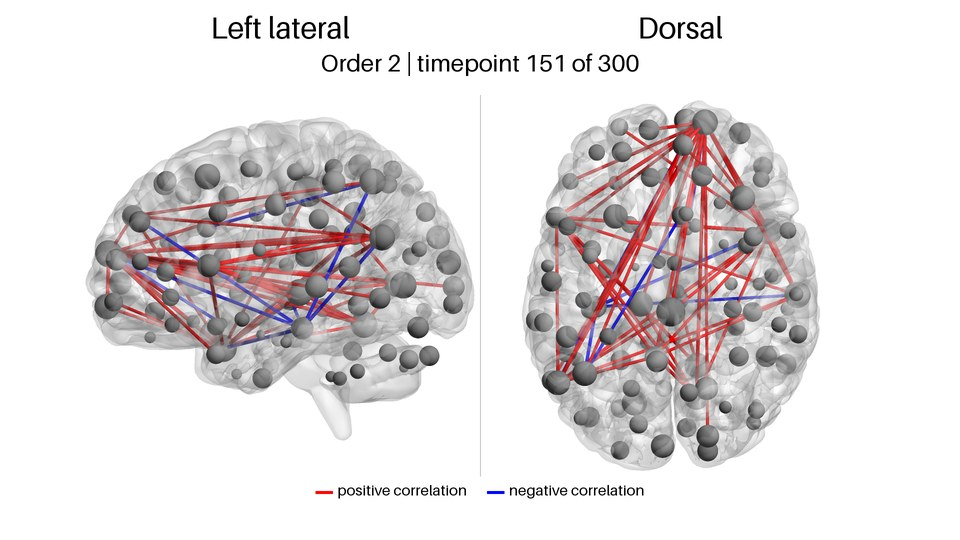

In [10]:
(points, edges), options = movie(2, [T // 2])
options.update(sizes=options['sizes'][0], caption=options.pop('captions')[0])
show_image(plot_network(points, edges[0], **options), width=960)

The four videos (orders 1 to 4):

In [11]:
for k in range(1, 5):
    tc.show_video(render(k))
    if QUALITY == 'preview':
        show_full_quality(k)

order 1: drawing 300 frames with 3 worker(s)


order 1: 300 frames of 1920 x 1080 at 30 fps (10.0 s), rendered in 72 s; htfa_order1.mp4: 3.2 MB


order 2: drawing 300 frames with 3 worker(s)


order 2: 300 frames of 1920 x 1080 at 30 fps (10.0 s), rendered in 66 s; htfa_order2.mp4: 4.3 MB


order 3: drawing 300 frames with 3 worker(s)


order 3: 300 frames of 1920 x 1080 at 30 fps (10.0 s), rendered in 119 s; htfa_order3.mp4: 0.7 MB


order 4: drawing 300 frames with 3 worker(s)


order 4: 300 frames of 1920 x 1080 at 30 fps (10.0 s), rendered in 133 s; htfa_order4.mp4: 0.7 MB


## 7. Values over time

The left panel shows the mean `|r|` over all pairs of features at each order, and the right panel the mean drawn value of the features of orders 2 to 4, each divided by its largest value. Near the start and the end of the recording, the kernels are cut off by the edges of the recording.

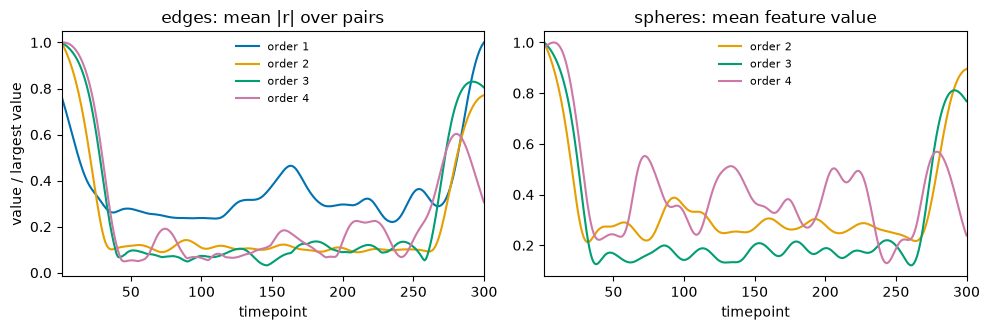

In [12]:
COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']   # Okabe-Ito
time_axis = np.arange(1, T + 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for k in range(1, 5):
    i, j = np.triu_indices(R[k].shape[0], 1)
    mean_r = np.abs(R[k][i, j, :]).mean(axis=0)
    left.plot(time_axis, mean_r / mean_r.max(), color=COLORS[k - 1], label=f'order {k}')
for k in range(2, 5):
    mean_value = values[k].mean(axis=1)
    right.plot(time_axis, mean_value / mean_value.max(), color=COLORS[k - 1], label=f'order {k}')
left.set_title('edges: mean |r| over pairs')
right.set_title('spheres: mean feature value')
for ax in (left, right):
    ax.set_xlabel('timepoint')
    ax.set_xlim(1, T)
    ax.legend(fontsize=8, frameon=False)
left.set_ylabel('value / largest value')
plt.tight_layout()
plt.show()

The picture on this tutorial's card in the gallery: the left lateral view of the order-2 network in the middle of the recording.

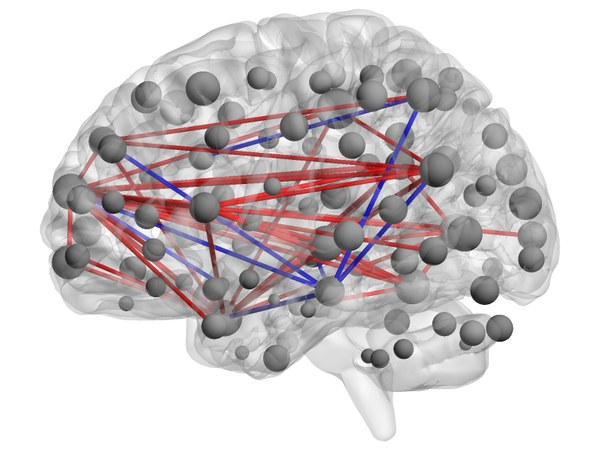

In [13]:
points, radii, colors, edge_matrix = scene(2, T // 2)
view = plot_network(points, edge_matrix, sizes=radii, radius_kb=(1.0, 0.0), node_color=colors, snap=False,
                    threshold=0.0, view='left', size=VIEW_SIZE, supersample=SUPERSAMPLE)
view = view.crop(htfa.content_box([view], margin=12))
width = max(view.width, round(view.height * 4 / 3))   # a white 4:3 canvas around it
card = PILImage.new('RGB', (width, round(width * 3 / 4)), 'white')
card.paste(view, ((card.width - view.width) // 2, (card.height - view.height) // 2))
show_image(card, width=600)

In [14]:
print(f'total run time: {(time.time() - NOTEBOOK_START) / 60:.0f} min')

total run time: 9 min
